## Parte C. Verificación con gráficas

P3(1.5) = 0.416667
P10(1.5) = 0.405435
P10(2.5) = -2.403097


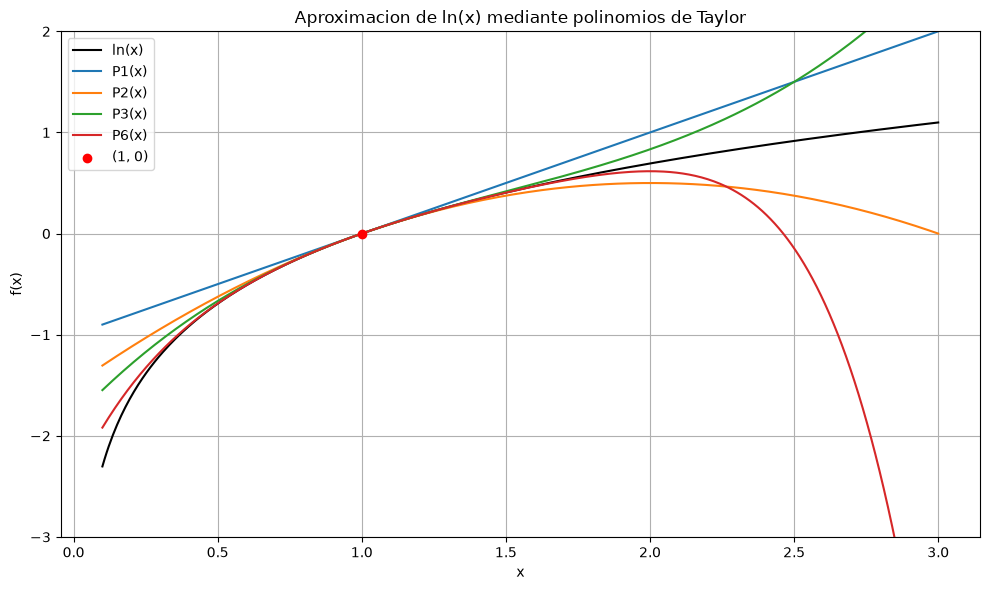

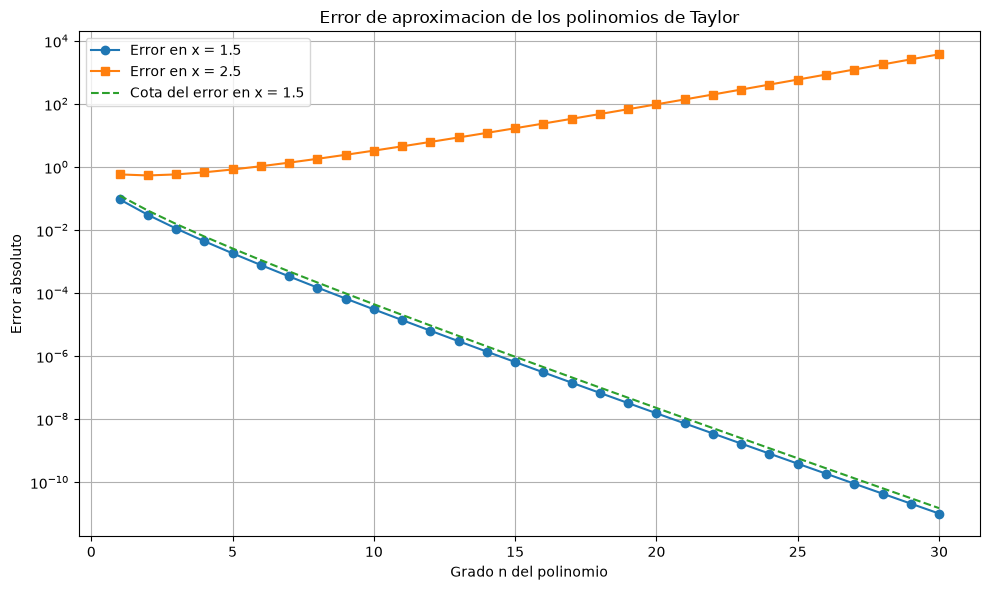

Menor grado: 15
Error: 6.487369870189497e-07


In [1]:
import numpy as np
import matplotlib.pyplot as plt


def taylor_ln(x, n):
    """Polinomio de Taylor de grado n de ln(x) alrededor de x0 = 1."""
    suma = 0

    for k in range(1, n + 1):
        suma += ((-1)**(k+1) / k) * (x-1)**k

    return suma


# Verificacion de los valores
print(f"P3(1.5) = {taylor_ln(1.5, 3):.6f}")
print(f"P10(1.5) = {taylor_ln(1.5, 10):.6f}")
print(f"P10(2.5) = {taylor_ln(2.5, 10):.6f}")


# GRAFICA 1: Polinomios de Taylor

x = np.linspace(0.1, 3, 400)

plt.figure(figsize=(10, 6))

plt.plot(x, np.log(x), label="ln(x)", color="black")
plt.plot(x, taylor_ln(x, 1), label="P1(x)")
plt.plot(x, taylor_ln(x, 2), label="P2(x)")
plt.plot(x, taylor_ln(x, 3), label="P3(x)")
plt.plot(x, taylor_ln(x, 6), label="P6(x)")

plt.scatter(1, 0, color="red", label="(1, 0)", zorder=5)

plt.ylim(-3, 2)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Aproximacion de ln(x) mediante polinomios de Taylor")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grafica1_taylor.png", dpi=300)
plt.show()


# GRAFICA 2: Error de aproximacion

grados = np.arange(1, 31)

error_15 = np.array([
    abs(np.log(1.5) - taylor_ln(1.5, n))
    for n in grados
])

error_25 = np.array([
    abs(np.log(2.5) - taylor_ln(2.5, n))
    for n in grados
])

cota = 0.5**(grados + 1) / (grados + 1)

plt.figure(figsize=(10, 6))

plt.semilogy(grados, error_15, "o-", label="Error en x = 1.5")
plt.semilogy(grados, error_25, "s-", label="Error en x = 2.5")
plt.semilogy(grados, cota, "--", label="Cota del error en x = 1.5")

plt.xlabel("Grado n del polinomio")
plt.ylabel("Error absoluto")
plt.title("Error de aproximacion de los polinomios de Taylor")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.savefig("grafica2_error.png", dpi=300)
plt.show()


# Menor grado que cumple la tolerancia

for n in grados:
    error = abs(np.log(1.5) - taylor_ln(1.5, n))

    if error < 10**(-6):
        print("Menor grado:", n)
        print("Error:", error)
        break